In [1]:
# Decision Tree Classifier
# Datasets:
#   - Titanic: ../Datasets/Titanic-Dataset.csv
#   - Breast Cancer Wisconsin: built into sklearn, no download needed

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.datasets import load_breast_cancer


Accuracy: 0.7877094972067039

Confusion Matrix:
 [[103   7]
 [ 31  38]]

Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.94      0.84       110
           1       0.84      0.55      0.67        69

    accuracy                           0.79       179
   macro avg       0.81      0.74      0.76       179
weighted avg       0.80      0.79      0.78       179



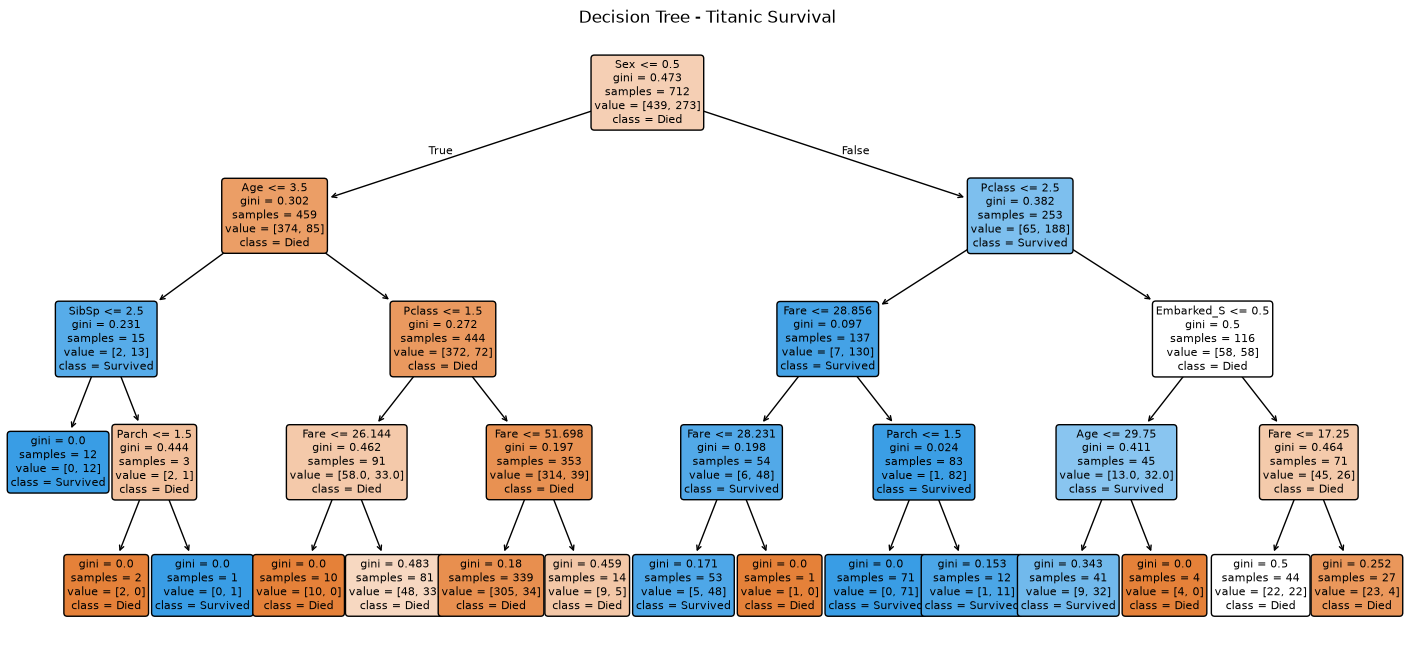

      Feature  Importance
1         Sex    0.576297
0      Pclass    0.195920
2         Age    0.106957
5        Fare    0.063141
7  Embarked_S    0.037198
3       SibSp    0.012109
4       Parch    0.008377
6  Embarked_Q    0.000000


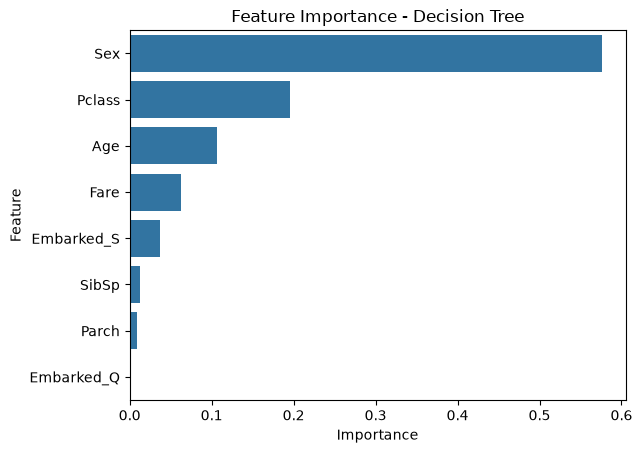

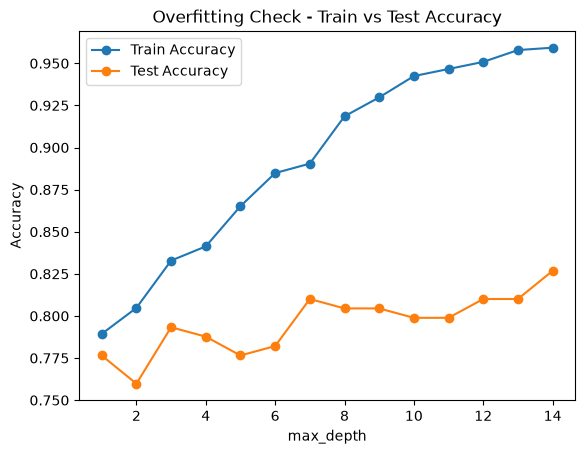

In [3]:
# ============================================================
# PART 1 - Titanic (Decision Tree doesn't need scaling, unlike KNN/Logistic Reg)
# ============================================================

df = pd.read_csv("../Datasets/Titanic-Dataset.csv")

df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df = pd.get_dummies(df, columns=["Embarked"], drop_first=True)

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare",
            "Embarked_Q", "Embarked_S"]
X = df[features]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ---- 1. Fit a Decision Tree ----
# no scaling needed here - trees split on raw feature values, not distances
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

# ---- 2. Predict and evaluate ----
y_pred = tree.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# ---- 3. Visualize the tree ----
# limited to max_depth=4 above specifically so this plot stays readable
plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=features, class_names=["Died", "Survived"],
          filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree - Titanic Survival")
plt.show()

# ---- 4. Feature importance ----
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": tree.feature_importances_
}).sort_values("Importance", ascending=False)

print(importance_df)

sns.barplot(x="Importance", y="Feature", data=importance_df)
plt.title("Feature Importance - Decision Tree")
plt.show()
# ---- 5. Check if max_depth matters (overfitting check) ----
depths = range(1, 15)
train_acc = []
test_acc = []

for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42)
    t.fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, t.predict(X_train)))
    test_acc.append(accuracy_score(y_test, t.predict(X_test)))

plt.plot(depths, train_acc, marker="o", label="Train Accuracy")
plt.plot(depths, test_acc, marker="o", label="Test Accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Overfitting Check - Train vs Test Accuracy")
plt.legend()
plt.show()

# train accuracy keeps climbing with depth, test accuracy plateaus/drops -
# classic sign of overfitting once the tree gets too deep




(569, 31)
target
1    357
0    212
Name: count, dtype: int64
Accuracy: 0.9385964912280702

Confusion Matrix:
 [[39  3]
 [ 4 68]]

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.93      0.92        42
           1       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114

                 Feature  Importance
20          worst radius    0.733548
27  worst concave points    0.122028
11         texture error    0.045785
21         worst texture    0.032319
26       worst concavity    0.017161
7    mean concave points    0.013327
13            area error    0.012704
1           mean texture    0.011846
28        worst symmetry    0.011282
3              mean area    0.000000


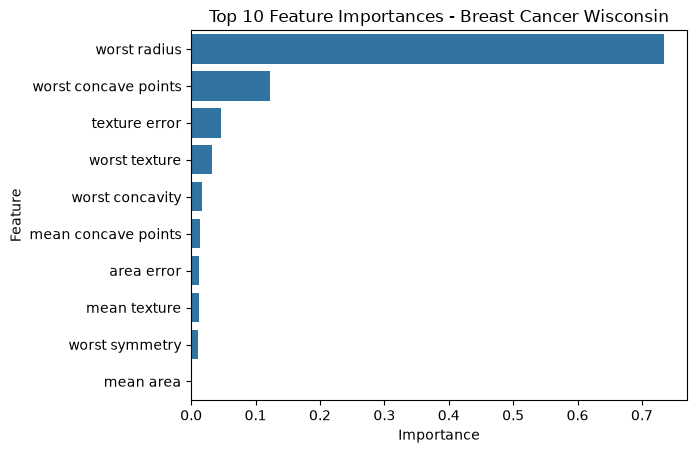

In [4]:
# ============================================================
# PART 2 - Breast Cancer Wisconsin (binary classification, sklearn built-in)
# ============================================================

cancer = load_breast_cancer()
cancer_df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
cancer_df["target"] = cancer.target   # 0 = malignant, 1 = benign

print(cancer_df.shape)
print(cancer_df["target"].value_counts())

Xc = cancer_df.drop(columns=["target"])
yc = cancer_df["target"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc
)

# ---- 6. Fit Decision Tree ----
tree_cancer = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_cancer.fit(Xc_train, yc_train)

# ---- 7. Predict and evaluate ----
yc_pred = tree_cancer.predict(Xc_test)
print("Accuracy:", accuracy_score(yc_test, yc_pred))
print("\nConfusion Matrix:\n", confusion_matrix(yc_test, yc_pred))
print("\nClassification Report:\n", classification_report(yc_test, yc_pred))

# ---- 8. Top 10 most important features ----
importance_cancer = pd.DataFrame({
    "Feature": cancer.feature_names,
    "Importance": tree_cancer.feature_importances_
}).sort_values("Importance", ascending=False).head(10)

print(importance_cancer)

sns.barplot(x="Importance", y="Feature", data=importance_cancer)
plt.title("Top 10 Feature Importances - Breast Cancer Wisconsin")
plt.show()

# "worst concave points" / "mean concave points" type features are usually
# the strongest predictors in this dataset